# CHANDAN MUKHERJEE
      MTech (IT), BTech (CSE), Diploma (Electrical)
      AWS Certified Solutions Architect - Associate
      AWS Certified Cloud Practitioner
      Microsoft Certified Azure Fundamentals
      SCJP (Java), Oracle (SQL) GLOBAL CERTIFIED
      Microsoft Certified Innovative Educator
      IBM Certification on Cloud, Docker, Kubernetes, Serverless, Python

<h1> Business Scenario: E-Commerce Sales Analysis </h1>

<b>Imagine you are working as a Data Analyst for an e-commerce company.</b>

<b>The company sells:</b>

Electronics <br>
Furniture <br>
Office Supplies <br>
Accessories


<b>It operates in:</b>

North <br>
South <br>
East <br>
West

<b>And sells through:</b>

Online <br>
Store (Retail Store) <br>
Big mall (Distributor)

<h1>Management has given you the following problem:</h1>

<h3>Our sales are increasing, but we don't know which products, regions, channels, and customer segments are actually driving revenue and profit. We also want to identify areas where sales are high but profit is low." </h3>

<h1> Understand the Business Questions </h1>

<h5>
Question 1 : How are sales changing over time?

Question 2 : Which product category generates the highest revenue?

Question 3 : What are the relationship between sales and profit?

Question 4 : How the sales per order are distributed?

Question 5 : Which regions are performing better?

Question 6 : Which product categories perform well in each region?

Question 7 : Which variables are strongly related to each other?

Question 8 : Does discount affect profit?

Question 9 : Can management interactively explore the data?

</h5>

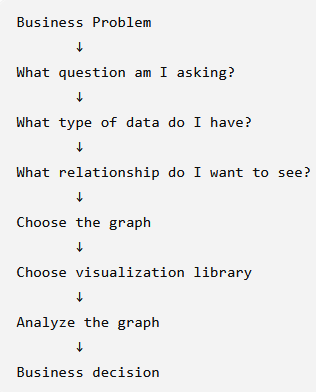

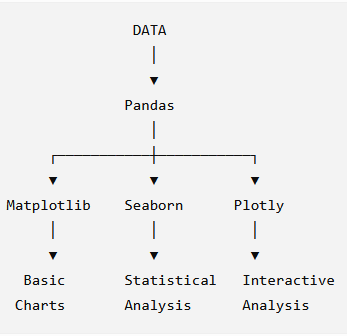

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


<h3> Importing Necessary Libraries </h3>

In [ ]:
import pandas as pd

<h3> Reading Data </h3>

In [ ]:
file_path="/content/drive/MyDrive/Colab Notebooks/business_sales_2000_rows.csv"

# Reading Data
df = pd.read_csv(file_path)

In [ ]:
print(df.head())

   Order_ID  Order_Date Region         Category       Channel  \
0     50525  2025-01-01   East      Accessories   Distributor   
1     50933  2025-01-01  South        Furniture  Retail Store   
2     50804  2025-01-01  North      Electronics   Distributor   
3     50614  2025-01-01   East      Accessories  Retail Store   
4     51691  2025-01-01  North  Office Supplies        Online   

  Customer_Segment  Customer_ID  Quantity  Unit_Price_USD  Discount_Rate  \
0   Small Business         1001        10           86.36          0.164   
1   Small Business         1359         3          255.44          0.162   
2   Small Business         1091         4          516.34          0.191   
3        Corporate         1266         6           97.68          0.071   
4        Corporate         1416        12           81.36          0.108   

   Sales_USD  Cost_USD  Profit_USD  Profit_Margin    Month  
0     721.97    444.76      277.21         0.3840  2025-01  
1     642.18    366.39      27

In [ ]:
print(df.shape)

(2000, 15)


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2000 non-null   int64  
 1   Order_Date        2000 non-null   object 
 2   Region            2000 non-null   object 
 3   Category          2000 non-null   object 
 4   Channel           2000 non-null   object 
 5   Customer_Segment  2000 non-null   object 
 6   Customer_ID       2000 non-null   int64  
 7   Quantity          2000 non-null   int64  
 8   Unit_Price_USD    2000 non-null   float64
 9   Discount_Rate     2000 non-null   float64
 10  Sales_USD         2000 non-null   float64
 11  Cost_USD          2000 non-null   float64
 12  Profit_USD        2000 non-null   float64
 13  Profit_Margin     2000 non-null   float64
 14  Month             2000 non-null   object 
dtypes: float64(6), int64(3), object(6)
memory usage: 234.5+ KB
None


<h1>Basic Business Analysis</h1>

<b> This gives management a basic picture.</b>

<b>For example:</b>

<ul>

<li> Total Sales       → How much money did we generate? </li>

<li>Total Profit      → How much money did we actually make? </li>

<li>Average Order     → How valuable is a typical order?</li>

<li>Total Quantity    → How many products did we sell?</li>

</ul>

In [ ]:
print("Total Sales:", df["Sales_USD"].sum())
print("Total Profit:", df["Profit_USD"].sum())
print("Average Order Value:", df["Sales_USD"].mean())
print("Total Quantity:", df["Quantity"].sum())

Total Sales: 3195852.98
Total Profit: 1099210.34
Average Order Value: 1597.92649
Total Quantity: 14911


<h1> Visualization Using Matplotlib </h1>

<h3> Problem 1 — How are sales changing over time? </h3>

<h5>
Management wants to know:
Are sales increasing, decreasing, or remaining stable?
</h5>

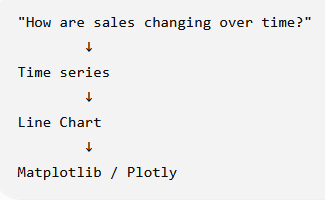

<h3> A line graph is appropriate because time is continuous. <h3>

In [ ]:
# First aggregate sales by month

monthly_sales = (
    df.groupby("Month")["Sales_USD"]
    .sum()
    .reset_index()
)

<h3> Importing Necessary Libraries </h3>

In [ ]:
import matplotlib.pyplot as plt

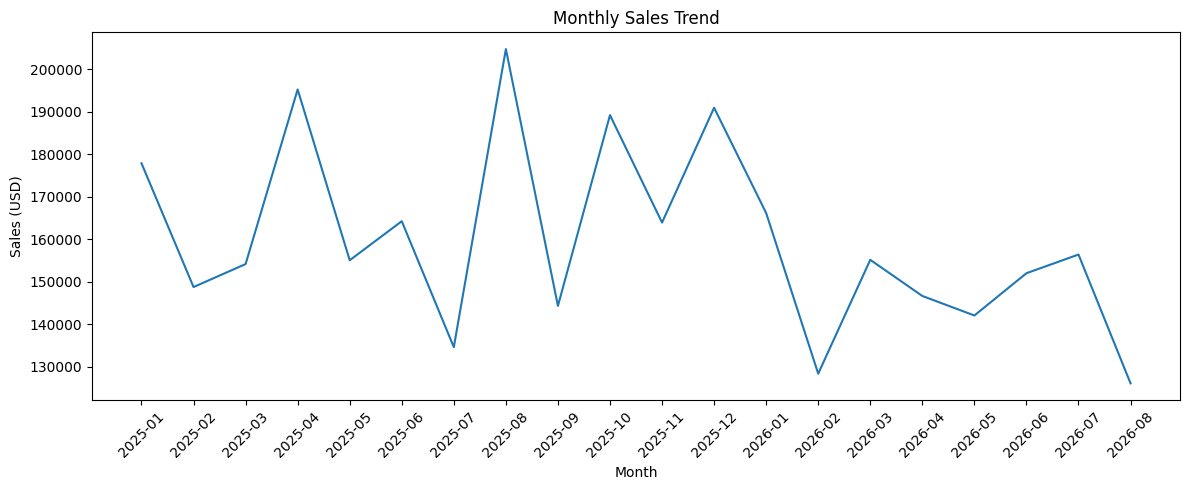

In [ ]:
# Visualize Using Line Chart

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Sales_USD"]
)

plt.xlabel("Month")
plt.ylabel("Sales (USD)")
plt.title("Monthly Sales Trend")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



<h3> Why Line Chart? </h3>

Because we're interested in: Jan → Feb → Mar → Apr → May → ... [ The order matters.]

<h5>
A bar chart could show monthly sales, but a line graph makes the trend easier to recognize.</h5>

<h3> Management can then investigate:</h3>

<ul>
<li> seasonal demand </li>
<li>promotions </li>
<li> holidays </li>
<li> marketing campaigns </li>
<li> supply problems </li>

<h3> Problem 2 - Which product category generates the highest revenue? </h3>

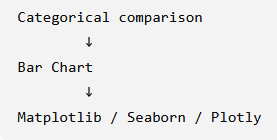

In [ ]:
category_sales = (
    df.groupby("Category")["Sales_USD"]
    .sum()
    .sort_values(ascending=False)
)

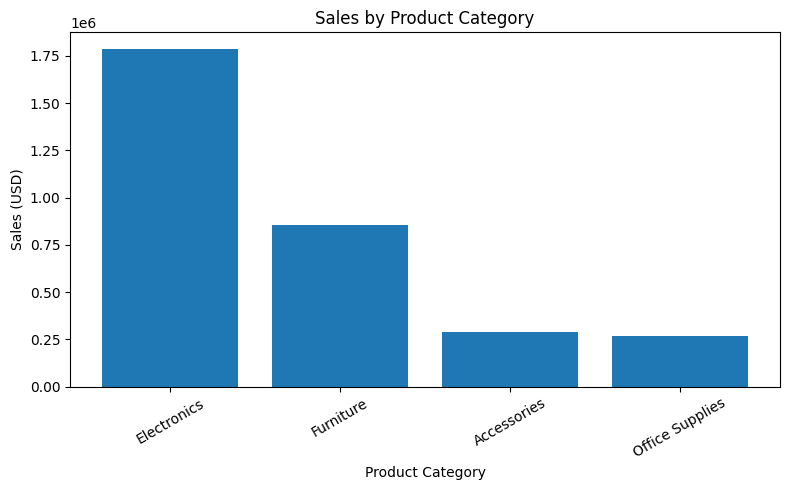

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_sales.index,
    category_sales.values
)

plt.xlabel("Product Category")
plt.ylabel("Sales (USD)")
plt.title("Sales by Product Category")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

<h3> Business decision </h3>

Here Electronics has the highest sales.

The company might:

<ul>
<li> increase electronics inventory </li>
<li> advertise electronics more </li>
<li> negotiate better supplier prices </li>
<li> introduce additional electronics products </li>
</ul>

<h2> High sales doesn't necessarily mean high profit. </h2>

<h2> Problem 3 : What are the relationship between Sales and Profit <h2>

In [ ]:
category_performance = (
    df.groupby("Category")[["Sales_USD", "Profit_USD"]]
    .sum()
)

print(category_performance)

                  Sales_USD  Profit_USD
Category                               
Accessories       290345.05   121590.62
Electronics      1784818.95   535413.55
Furniture         854371.25   322487.10
Office Supplies   266317.73   119719.07


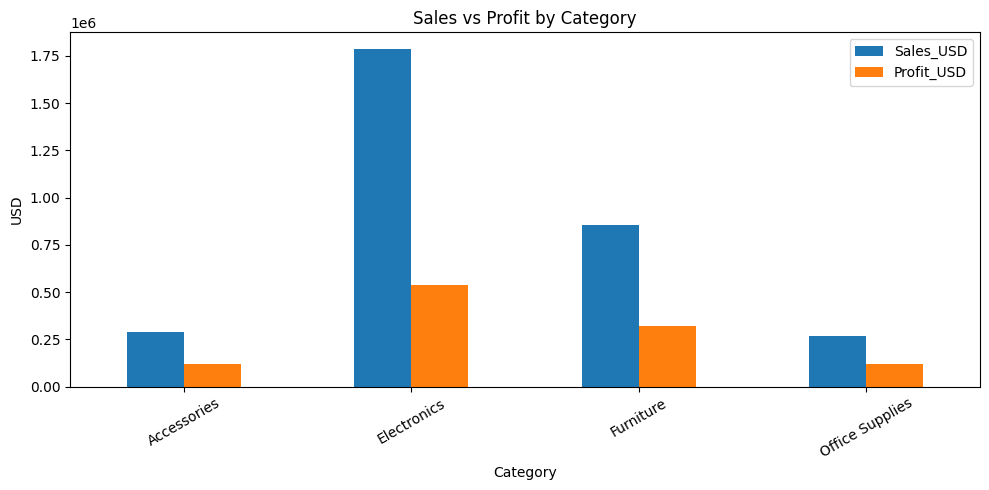

In [ ]:
category_performance.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Category")
plt.ylabel("USD")
plt.title("Sales vs Profit by Category")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

<h3> A product can generate huge revenue but have: </h3>

<ul>
<li> high manufacturing cost </li>
<li> high discount </li>
<li> low margin </li>

Therefore:

<h3>
Revenue alone should not be used to judge business performance. </h3>

<h2> Problem 4: How the sales per order are distributed? </h2>

<h4>
Management asks:
"Are most orders small, medium, or very large?" </h4>

<h3> Seaborn is particularly useful for statistical visualization. </h3>



<h3> Importing Necessary Libraries </h3>

In [ ]:
import seaborn as sns

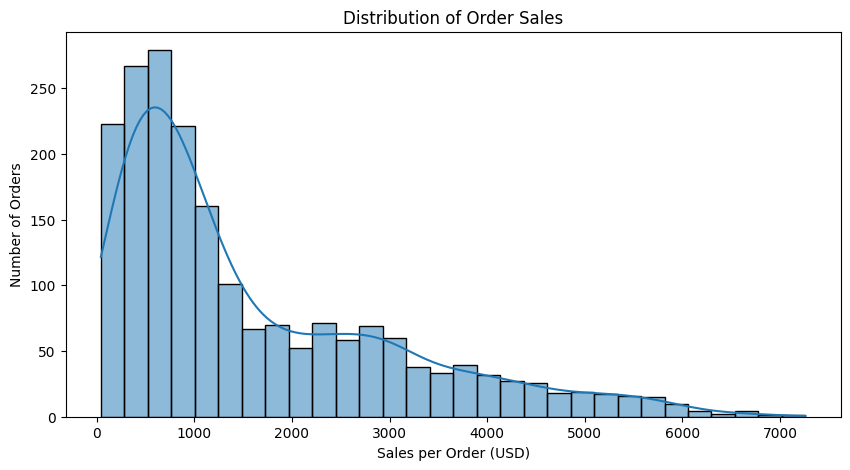

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Sales_USD",
    bins=30,
    kde=True
)

plt.xlabel("Sales per Order (USD)")
plt.ylabel("Number of Orders")
plt.title("Distribution of Order Sales")

plt.show()

<h1> Seaborn Box Plot — Finding Outliers </h1>

<h3> Are there unusually large or unusually small orders? </h3>

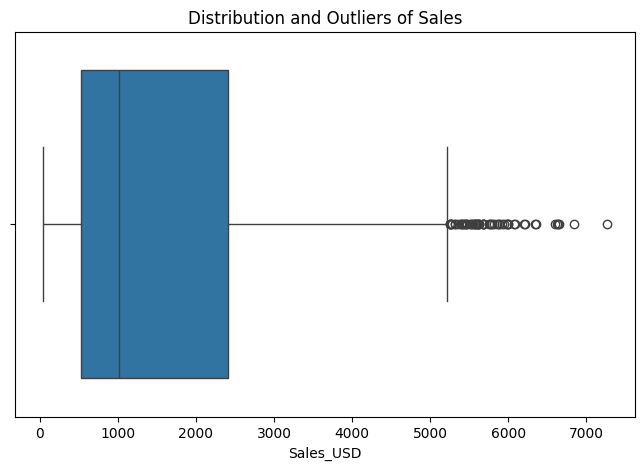

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Sales_USD"
)

plt.title("Distribution and Outliers of Sales")

plt.show()

<h2> A box plot helps identify: </h2>

<ul>
<li> Median </li>
<li> Lower quartile </li>
<li> Upper quartile </li>
<li> Spread </li>
<li> Potential outliers </li>
</ul>

<h2> Business importance </h2>

<h3>You find several extremely large orders. </h3>

<h4> You can investigate: </h4>

Are these genuine corporate orders?
or Are these data-entry errors?

<h1> Problem 5 : Which regions are performing better?</h1>



In [ ]:
region_sales = (
    df.groupby("Region")["Sales_USD"]
    .sum()
    .reset_index()
)

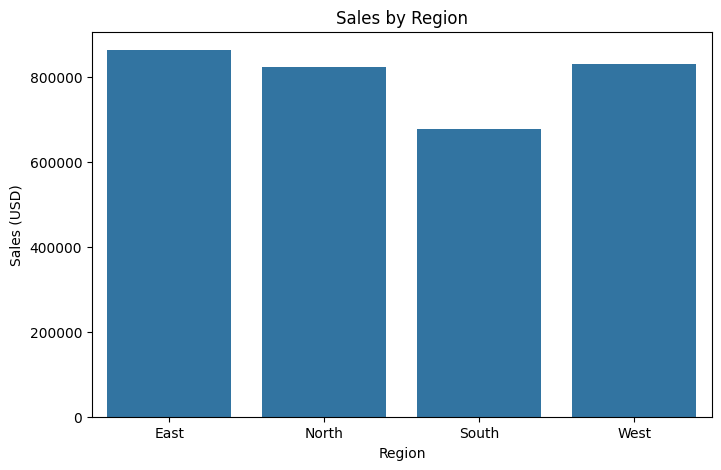

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=region_sales,
    x="Region",
    y="Sales_USD"
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales (USD)")

plt.show()

<h1> Problem 6 : Which product categories perform well in each region? </h1>

<h3>
Sales by Category and Region </h3>

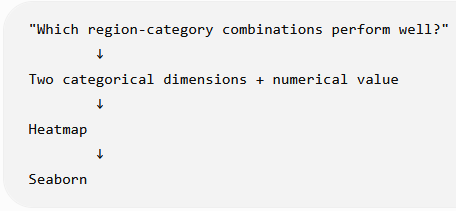

In [ ]:
pivot = df.pivot_table(
    values="Sales_USD",
    index="Region",
    columns="Category",
    aggfunc="sum"
)

print(pivot)

Category  Accessories  Electronics  Furniture  Office Supplies
Region                                                        
East         83513.98    492728.50  226357.41         60923.80
North        53938.72    462125.58  233970.65         74117.99
South        71619.23    372459.46  170502.33         64017.57
West         81273.12    457505.41  223540.86         67258.37


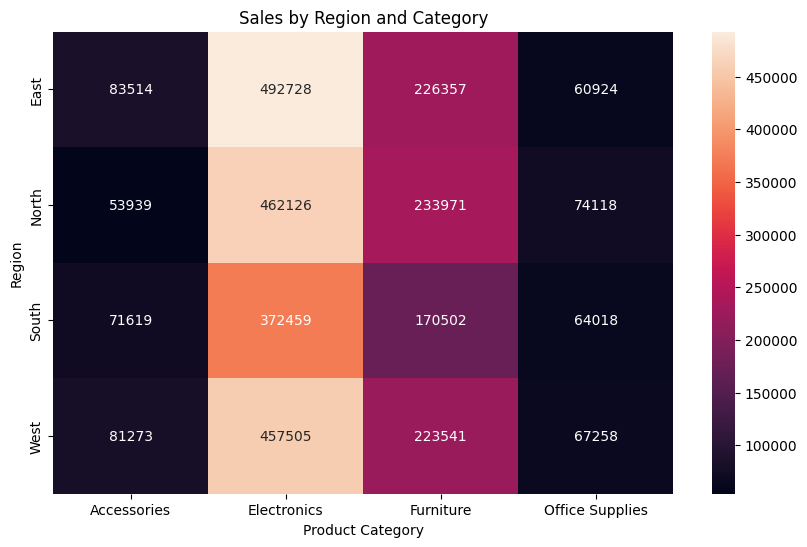

In [ ]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".0f"
)

plt.title("Sales by Region and Category")
plt.xlabel("Product Category")
plt.ylabel("Region")

plt.show()

Region <br>
   ↓ <br>
North     Electronics and Furniture <br>
South     Electronics and Furniture <br>

<h2> Business question answered </h2>

<h3>
"Electronics performs particularly strongly in certain regions, while some categories have relatively weak sales."
</h3>

This can influence:
<ul>
<li> regional marketing </li>
<li> inventory allocation </li>
<li> pricing </li>
<li> product availability </li>
</ul>

<h1> Problem 7 : Which numerical variables are related to each other? </h1>

<h2> Correlation Heatmap <h2>

In [ ]:
numeric_columns = [
    "Quantity",
    "Unit_Price_USD",
    "Discount_Rate",
    "Sales_USD",
    "Cost_USD",
    "Profit_USD",
    "Profit_Margin"
]

correlation = df[numeric_columns].corr()

In [ ]:
print(correlation)

                Quantity  Unit_Price_USD  Discount_Rate  Sales_USD  Cost_USD  \
Quantity        1.000000       -0.003299      -0.008045   0.590543  0.551554   
Unit_Price_USD -0.003299        1.000000      -0.001846   0.706299  0.726677   
Discount_Rate  -0.008045       -0.001846       1.000000  -0.066940 -0.060567   
Sales_USD       0.590543        0.706299      -0.066940   1.000000  0.995170   
Cost_USD        0.551554        0.726677      -0.060567   0.995170  1.000000   
Profit_USD      0.658083        0.633910      -0.079061   0.974499  0.947763   
Profit_Margin   0.008536       -0.853384       0.002339  -0.593509 -0.641812   

                Profit_USD  Profit_Margin  
Quantity          0.658083       0.008536  
Unit_Price_USD    0.633910      -0.853384  
Discount_Rate    -0.079061       0.002339  
Sales_USD         0.974499      -0.593509  
Cost_USD          0.947763      -0.641812  
Profit_USD        1.000000      -0.461411  
Profit_Margin    -0.461411       1.000000  


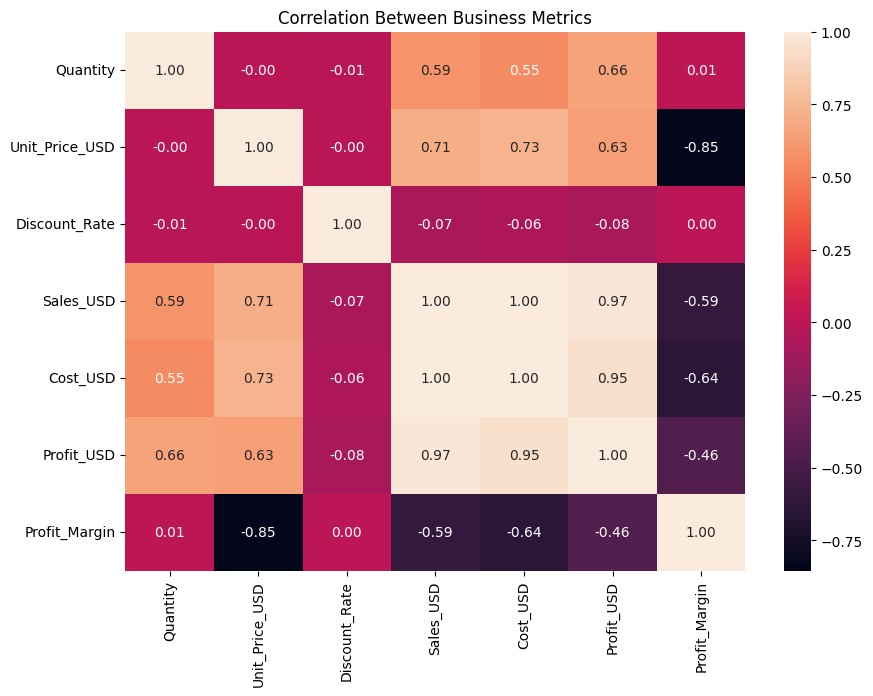

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Business Metrics")

plt.show()

<h1> Problem 8 : Does Discount Reduce Profit? </h1>

<h3>
Management says: <br>

"We give customers discounts to increase sales. But are these discounts actually helping us?"
</h3>

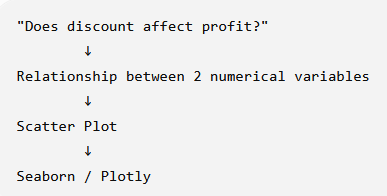

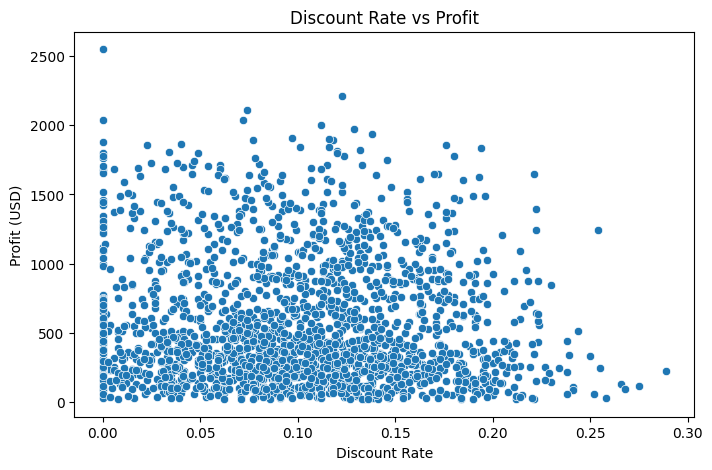

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Discount_Rate",
    y="Profit_USD"
)

plt.xlabel("Discount Rate")
plt.ylabel("Profit (USD)")
plt.title("Discount Rate vs Profit")

plt.show()

<h2> Improve the Analysis With Hue </h2>

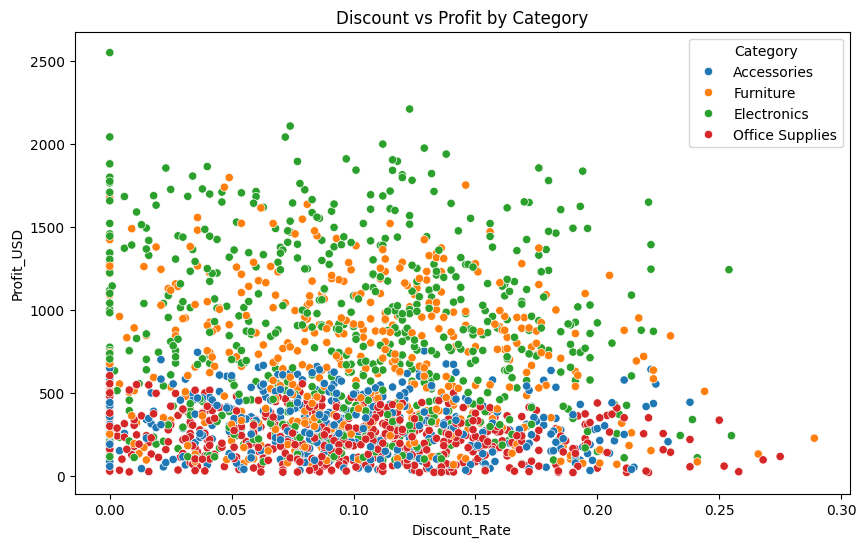

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Discount_Rate",
    y="Profit_USD",
    hue="Category"
)

plt.title("Discount vs Profit by Category")
plt.show()

<h3>
Does the relationship between discount and profit differ between product categories? </h3>

<h4> What is your opinion? </h4>

<h1> Interactive Visualization <h1>

<h3>
Management wants an interactive visualization.

Instead of a static graph.</h3>

<h3> An interactive graph. Hover over points, zoom in, and explore the data. </h3>

<h3> Importing Necessary Libraries </h3>

In [ ]:
import plotly.express as px

<h3> Plotly Interactive Sales Chart </h3>

In [ ]:
fig = px.line(
    monthly_sales,
    x="Month",
    y="Sales_USD",
    title="Interactive Monthly Sales Trend"
)

fig.show()

<h3> Plotly Interactive Category Chart </h3>

In [ ]:
fig = px.bar(
    category_sales.reset_index(),
    x="Category",
    y="Sales_USD",
    title="Sales by Product Category"
)

fig.show()

<h3> Plotly — Interactive Scatter Plot </h3>

In [ ]:
fig = px.scatter(
    df,
    x="Discount_Rate",
    y="Profit_USD",
    color="Category",
    hover_data=[
        "Region",
        "Channel",
        "Customer_Segment",
        "Sales_USD"
    ],
    title="Discount Rate vs Profit"
)

fig.show()

<h3> Plotly — Add Region </h3>

In [ ]:
fig = px.scatter(
    df,
    x="Sales_USD",
    y="Profit_USD",
    color="Region",
    size="Quantity",
    hover_data=["Category", "Channel"],
    title="Sales vs Profit by Region"
)

fig.show()